# Quantum Commerce — Treinando o modelo de análise de sentimento no Google Colab

**O que você vai fazer aqui:** treinar, do zero, o modelo que classifica as avaliações da Quantum Commerce como **positiva**, **neutra** ou **negativa** — o mesmo modelo que o backend da loja usa no endpoint `POST /predict`.

**O que você vai aprender, passo a passo:**

1. Carregar datasets reais (~100 mil avaliações em português no Olist, +132 mil no B2W)
2. Explorar os dados e transformar estrelas (1–5) em rótulos (negativo / neutro / positivo)
3. Transformar texto em números com TF-IDF
4. Treinar um *baseline* — o "chute honesto" que todo modelo precisa superar
5. Treinar o modelo principal: Regressão Logística
6. Comparar com uma rede neural simples (MLP)
7. Avaliar com F1-macro e matriz de confusão, e interpretar o resultado
8. **Comparar as 3 versões do treino e escolher com números (Passo 11)**
9. Salvar o modelo treinado no Drive

**Como rodar:** no Colab, menu **Ambiente de execução → Executar tudo**. Não precisa de GPU — CPU comum basta, e o treino todo leva uns 10–15 minutos (o Passo 11 treina o modelo 4 vezes).

**De onde vêm os dados:** o arquivo `olist_order_reviews_dataset.csv` já está no seu Drive, na pasta `TRABALHO-FINAL/archive/`; `b2w.csv` e `buscape.csv` estão em `TRABALHO-FINAL/archive-v2/`. O notebook monta o Drive e lê de lá — nada precisa ser baixado.

**Resultado esperado (para conferir no final):** a versão 3 (Olist + B2W, o treino oficial) com **F1-macro ~0,637** no teste do Olist e **19/24 no golden set** da loja. A versão 1 (só Olist, Passos 1–10) dá F1-macro ~0,635 e 13/24 no golden — são os números de antes da mudança, guardados aqui como referência. O treino oficial do projeto (`backend/ml/train.py --olist --b2w`) usa um único split sobre os dados combinados e marca F1-macro 0,662 no teste misto e 20/24 no golden — a diferença para os 19/24 da v3 aqui é o split, não o modelo.


## Passo 0 — O ambiente: o que já vem pronto no Colab

O Colab já traz Python com `pandas`, `scikit-learn` e `matplotlib` instalados. A célula abaixo só confere as versões — se um dia você rodar este notebook fora do Colab, é isso que precisa estar instalado.

In [ ]:
import sys
import sklearn
import pandas as pd
import matplotlib

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)

Python: 3.13.18
pandas: 2.2.3
scikit-learn: 1.6.1
matplotlib: 3.10.0


## Passo 1 — Montar o Google Drive e apontar para o arquivo

O Colab roda numa máquina do Google, que não enxerga o seu Drive sozinha. A célula abaixo pede a sua autorização e monta o Drive em `/content/drive` — é como "plugar" o seu Drive na máquina do Colab. Vai aparecer um link para autorizar e um campo para colar o código.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
CAMINHO_CSV = '/content/drive/MyDrive/FIAP-MBA/Disciplinas/2-MACHINE LEARNING FOUNDATIONS AND CLASSICAL MODELS/TRABALHO-FINAL/archive/olist_order_reviews_dataset.csv'
CAMINHO_B2W = '/content/drive/MyDrive/FIAP-MBA/Disciplinas/2-MACHINE LEARNING FOUNDATIONS AND CLASSICAL MODELS/TRABALHO-FINAL/archive-v2/b2w.csv'
CAMINHO_BUSCAPE = '/content/drive/MyDrive/FIAP-MBA/Disciplinas/2-MACHINE LEARNING FOUNDATIONS AND CLASSICAL MODELS/TRABALHO-FINAL/archive-v2/buscape.csv'
for nome, caminho in [('Olist', CAMINHO_CSV), ('B2W', CAMINHO_B2W), ('Buscapé', CAMINHO_BUSCAPE)]:
    print(('OK  ' if os.path.exists(caminho) else 'FALTA ') + nome + ': ' + caminho)


Mounted at /content/drive
Arquivo encontrado!
/content/drive/MyDrive/FIAP-MBA/Disciplinas/2-MACHINE LEARNING FOUNDATIONS AND CLASSICAL MODELS/TRABALHO-FINAL/archive/olist_order_reviews_dataset.csv


> **Se o arquivo não foi encontrado:** confira no Drive se a pasta se chama mesmo `TRABALHO-FINAL` e se dentro dela há a pasta `archive` com o `olist_order_reviews_dataset.csv`. Se o nome for outro, ajuste o `CAMINHO_CSV` na célula acima. Alternativa: faça upload do CSV direto no Colab com `from google.colab import files; files.upload()` e aponte o caminho para `/content/olist_order_reviews_dataset.csv`.

## Passo 2 — Carregar o CSV e olhar por dentro

`read_csv` lê o arquivo para um DataFrame do pandas — uma tabela em memória. `shape` diz quantas linhas e colunas há; `head` mostra as primeiras linhas para conferir se as colunas são as esperadas.

In [ ]:
df = pd.read_csv(CAMINHO_CSV)
print("Formato (linhas, colunas):", df.shape)
print("\nColunas:", list(df.columns))
df.head(3)

Formato (linhas, colunas): (99224, 7)

Colunas: ['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24


## Passo 3 — Explorar: quantas avaliações por nota? E quantas têm texto?

Dois fatos definem o projeto inteiro:

- **As notas são muito desbalanceadas:** a nota 5 domina. Um modelo que sempre chutasse "positivo" já acertaria ~58% — por isso precisamos de uma métrica melhor que a acurácia (ver Passo 7).
- **Nem toda avaliação tem texto:** sem texto, não dá para treinar um modelo de texto. Essas linhas serão descartadas no próximo passo.

In [ ]:
print("Avaliações por nota (1 a 5):")
print(df['review_score'].value_counts().sort_index())
print("\nDatas:", df['review_creation_date'].min(), "→", df['review_creation_date'].max())

tem_titulo = df['review_comment_title'].notna()
tem_mensagem = df['review_comment_message'].notna()
print("\nCom título:", tem_titulo.sum(), "| Com mensagem:", tem_mensagem.sum())
print("Com título OU mensagem:", (tem_titulo | tem_mensagem).sum())
print("Sem texto nenhum:", (~(tem_titulo | tem_mensagem)).sum(), "— essas serão descartadas no Passo 4")

Avaliações por nota (1 a 5):
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Datas: 2016-10-02 00:00:00 → 2018-08-31 00:00:00

Com título: 11568 | Com mensagem: 40977
Com título OU mensagem: 42706
Sem texto nenhum: 56518 — essas serão descartadas no Passo 4


## Passo 4 — Construir o texto e o rótulo de cada avaliação

Duas transformações acontecem aqui:

- **Texto = título + mensagem.** O título sozinho salva 1.737 avaliações que não têm mensagem. Juntar os dois é o que o treino oficial faz.
- **Rótulo = nota convertida em sentimento:** notas 1–2 → `negativo`, nota 3 → `neutro`, notas 4–5 → `positivo`.

Por que 3 classes e não 5 (uma por estrela)? Porque o que importa para a loja é o sentimento — e com 5 classes as fronteiras entre 4 e 5, ou entre 1 e 2, são ruído: o cliente que dá 4 ou 5 está satisfeito do mesmo jeito.

In [ ]:
def rotulo(nota):
    if nota <= 2:
        return "negativo"
    if nota == 3:
        return "neutro"
    return "positivo"

df['texto'] = (
    df['review_comment_title'].fillna('') + ' ' +
    df['review_comment_message'].fillna('')
).str.strip()
df['rotulo'] = df['review_score'].apply(rotulo)

dados = df[df['texto'] != ''][['texto', 'rotulo']].reset_index(drop=True)
print("Avaliações com texto:", len(dados), "de", len(df))
print("\nDistribuição dos rótulos:")
print(dados['rotulo'].value_counts())
print(dados['rotulo'].value_counts(normalize=True).round(3))
dados.head(10)

Avaliações com texto: 42687 de 99224

Distribuição dos rótulos:
rotulo
positivo    28050
negativo    10994
neutro       3643
Name: count, dtype: int64
rotulo
positivo    0.657
negativo    0.258
neutro      0.085
Name: proportion, dtype: float64


,texto,rotulo
0,Recebi bem antes do prazo estipulado.,positivo
1,Parabéns lojas lannister adorei comprar pela I...,positivo
2,recomendo aparelho eficiente. no site a marca ...,positivo
3,"Mas um pouco ,travando...pelo valor ta Boa.",positivo
4,"Super recomendo Vendedor confiável, produto ok...",positivo
5,"GOSTARIA DE SABER O QUE HOUVE, SEMPRE RECEBI E...",negativo
6,Não chegou meu produto Péssimo,negativo
7,Ótimo Loja nota 10,positivo
8,obrigado pela atençao amim dispensada,positivo
9,A compra foi realizada facilmente.\r\nA entreg...,positivo


## Passo 5 — Separar treino e teste (o teste nunca é usado para treinar)

- **80% treino / 20% teste**, sorteados com `random_state=42` (a semente fixa deixa o experimento reproduzível: todo mundo que rodar chega nos mesmos números).
- **`stratify`**: o sorteio respeita a proporção de cada classe nos dois conjuntos — o teste tem os mesmos ~66% de positivos que o treino.

O teste fica guardado até o final. Ele é a nossa única medida honesta de "o modelo aprendeu, ou só decorou o treino?".

In [ ]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    dados['texto'], dados['rotulo'],
    test_size=0.20, random_state=42, stratify=dados['rotulo'],
)
print("Treino:", len(X_treino), "| Teste:", len(X_teste))
print("\nProporção no treino:")
print(y_treino.value_counts(normalize=True).round(3))
print("\nProporção no teste:")
print(y_teste.value_counts(normalize=True).round(3))

Treino: 34149 | Teste: 8538

Proporção no treino:
rotulo
positivo    0.657
negativo    0.258
neutro      0.085
Name: proportion, dtype: float64

Proporção no teste:
rotulo
positivo    0.657
negativo    0.258
neutro      0.085
Name: proportion, dtype: float64


## Passo 6 — Transformar texto em números: TF-IDF

Modelos de machine learning não leem texto — leem números. O TF-IDF transforma cada avaliação num vetor:

- **Cada palavra (e cada par de palavras) vira uma coluna.** "não gostei" conta como uma feature só — por isso `ngram_range=(1, 2)`.
- **O peso de cada palavra** combina quantas vezes ela aparece na avaliação com o quão rara ela é no dataset inteiro. "produto" aparece em tudo e pesa pouco; "quebrado" é raro e pesa muito — é justamente o que distingue uma avaliação negativa.
- **`max_features=8000`**: só as 8.000 features mais informativas entram — o resto é ruído.
- **`min_df=2`**: palavra que aparece uma única vez no dataset inteiro é erro de digitação ou caso único — fora.
- **`sublinear_tf=True`**: atenua repetições ("muito muito muito bom" não vale 3× "muito bom").
- **`stop_words`**: palavras tão comuns ("de", "que", "o", "a") que não ajudam a distinguir sentimento — removidas antes de virar feature. A lista é a mesma do projeto (`backend/ml/stopwords.py`).

⚠️ **Detalhe que decide se o experimento é honesto:** `fit_transform` (aprender o vocabulário) é feito **só com o treino**. O teste passa por `transform` com o *mesmo* vocabulário. Se o vocabulário fosse aprendido com o teste junto, o modelo "veria" o teste antes da hora — é o chamado **vazamento de dados**.

In [ ]:
# Stopwords em português — as mesmas do projeto (backend/ml/stopwords.py).
STOPWORDS_PT = ['a', 'ao', 'aos', 'aquela', 'aquelas', 'aquele', 'aqueles', 'aquilo',
                'as', 'até', 'com', 'como', 'da', 'das', 'de', 'dela', 'delas', 'dele', 'deles',
                'depois', 'do', 'dos', 'e', 'ela', 'elas', 'ele', 'eles', 'em', 'entre', 'era', 'eram',
                'essa', 'essas', 'esse', 'esses', 'esta', 'estamos', 'estas', 'estava', 'estavam', 'este',
                'estes', 'estou', 'eu', 'foi', 'foram', 'há', 'isso', 'isto', 'já', 'lhe', 'lhes', 'mais',
                'mas', 'me', 'meu', 'meus', 'minha', 'minhas', 'muito', 'na', 'nas', 'nem', 'no', 'nos',
                'nossa', 'nossas', 'nosso', 'nossos', 'num', 'numa', 'o', 'os', 'ou', 'para', 'pela',
                'pelas', 'pelo', 'pelos', 'por', 'que', 'quem', 'se', 'seja', 'sejam', 'sem', 'seu', 'seus',
                'sobre', 'sua', 'suas', 'só', 'também', 'te', 'tem', 'têm', 'todo', 'todos', 'um', 'uma',
                'umas', 'uns', 'você', 'vocês', 'é', 'são', 'ser', 'está', 'estão', 'fui', 'vou', 'vai',
                'vou', 'era', 'foi', 'quando', 'onde', 'qual', 'quais', 'quanto', 'quantos', 'porque',
                'pois', 'então', 'ainda', 'mesmo', 'sempre', 'nunca', 'muito', 'pouco',
                'cada', 'outro', 'outra', 'outros', 'outras', 'nada', 'tudo', 'algum', 'alguma', 'alguns',
                'algumas', 'nenhum', 'nenhuma', 'esse', 'desse', 'dessa', 'disso', 'daqui', 'daí', 'lá',
                'aqui', 'ali', 'agora', 'hoje', 'ontem', 'amanhã', 'antes', 'depois']

#'não', 'mal', 'bem',

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vetorizador = TfidfVectorizer(
    ngram_range=(1, 2),        # palavras isoladas e pares ("não gostei")
    max_features=8000,         # só as 8.000 features mais informativas
    min_df=2,                  # ignora palavra que aparece 1 única vez
    sublinear_tf=True,         # atenua palavras repetidas muitas vezes
    stop_words=STOPWORDS_PT,   # remove "de", "que", "o", "a"...
    lowercase=True,            # "Ótimo" e "ótimo" viram a mesma palavra
)
X_treino_vec = vetorizador.fit_transform(X_treino)   # APRENDE o vocabulário SÓ com o treino
X_teste_vec = vetorizador.transform(X_teste)         # aplica o MESMO vocabulário ao teste
print("Vocabulário:", len(vetorizador.vocabulary_), "palavras/expressões")
print("Matriz de treino:", X_treino_vec.shape, "(linhas = avaliações, colunas = features)")

Vocabulário: 8000 palavras/expressões
Matriz de treino: (34149, 8000) (linhas = avaliações, colunas = features)


## Passo 7 — Baseline: o "chute honesto" que todo modelo precisa superar

Antes de qualquer modelo de verdade, treinamos um que **sempre prevê a classe mais comum** (positivo). Ele é o piso: se um modelo não ganhar dele, não aprendeu nada — só decorou a maioria.

A função `avaliar` abaixo será reutilizada para os três modelos. Ela mostra duas métricas:

- **Acurácia**: fração de acertos no total. Engana quando as classes são desbalanceadas (o baseline já faz 0,657 só chutando positivo).
- **F1-macro**: a média do F1 das três classes, cada classe valendo o mesmo. É a métrica principal do projeto — porque a classe neutra, com só 8,5% dos dados, vale tanto quanto a positiva.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

resultados = {}

def avaliar(nome, y_verdadeiro, y_previsto):
    acc = accuracy_score(y_verdadeiro, y_previsto)
    f1 = f1_score(y_verdadeiro, y_previsto, average='macro')
    resultados[nome] = {"accuracy": round(float(acc), 4), "f1_macro": round(float(f1), 4)}
    print(f"{nome:35s} acurácia={acc:.3f}  F1-macro={f1:.3f}")

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_treino_vec, y_treino)
pred_baseline = baseline.predict(X_teste_vec)
avaliar("Baseline (sempre positivo)", y_teste, pred_baseline)

Baseline (sempre positivo)          acurácia=0.657  F1-macro=0.264


## Passo 8 — O modelo principal: Regressão Logística

É o modelo do projeto. Para cada avaliação, ele calcula uma pontuação por classe a partir das palavras do TF-IDF e escolhe a maior. Dois parâmetros importam:

- **`C=4`**: controla a regularização. `C` maior = menos regularização = o modelo pode se ajustar mais aos dados de treino.
- **`class_weight='balanced'`**: compensa o desbalanceamento. A classe neutra, com só 8,5% do treino, passa a pesar mais no treino — sem isso, o modelo praticamente ignoraria os neutros.

In [ ]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(C=4, class_weight='balanced', max_iter=1000, random_state=42)
logreg.fit(X_treino_vec, y_treino)
pred_logreg = logreg.predict(X_teste_vec)
avaliar("Regressão Logística (TF-IDF)", y_teste, pred_logreg)

Regressão Logística (TF-IDF)        acurácia=0.806  F1-macro=0.654


## Passo 9 — Comparação: uma rede neural simples (MLP)

Para cumprir o tópico 2 do enunciado (clássico × rede neural), comparamos com um MLP — uma rede com **uma camada oculta de 128 neurônios**, sobre o mesmo TF-IDF.

⚠️ **Por que a MLP treina numa subamostra de 12.000 linhas?** O MLP do scikit-learn não trabalha com matriz esparsa: ele densifica o TF-IDF. Densificar as ~34 mil linhas de treino × 8.000 features passaria de 2 GB de memória. A subamostra é estratificada (mantém a proporção das classes) e o teste continua sendo o mesmo para os três modelos — então a comparação segue válida.

In [ ]:
from sklearn.neural_network import MLPClassifier

# Subamostra estratificada de 12.000 linhas do treino (ver nota acima).
X_mlp, _, y_mlp, _ = train_test_split(
    X_treino_vec, y_treino, train_size=12000, random_state=42, stratify=y_treino,
)
mlp = MLPClassifier(hidden_layer_sizes=(128,), max_iter=300, random_state=42)
mlp.fit(X_mlp, y_mlp)
pred_mlp = mlp.predict(X_teste_vec)
avaliar("MLP (1 camada, 128 neurônios)", y_teste, pred_mlp)

MLP (1 camada, 128 neurônios)       acurácia=0.814  F1-macro=0.622


## Passo 10 — Avaliar e interpretar: onde o modelo erra?

O relatório por classe mostra precisão e recall de cada sentimento. E a matriz de confusão mostra **para onde vão os erros**: cada linha é o rótulo verdadeiro, cada coluna é o que o modelo previu. A diagonal é o acerto; fora dela, a confusão.

              precision    recall  f1-score   support

    negativo       0.75      0.78      0.76      2199
      neutro       0.21      0.36      0.26       729
    positivo       0.94      0.84      0.88      5610

    accuracy                           0.78      8538
   macro avg       0.63      0.66      0.64      8538
weighted avg       0.83      0.78      0.80      8538



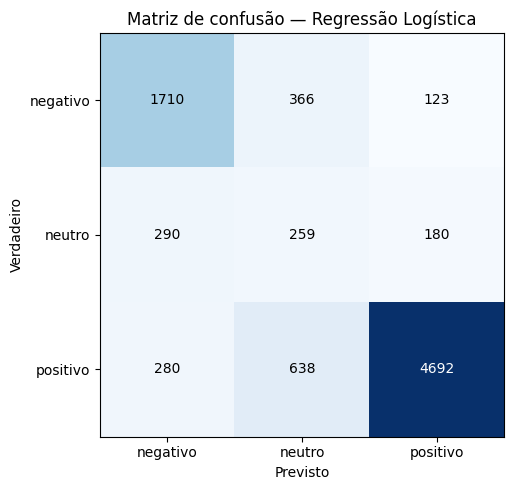

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

print(classification_report(y_teste, pred_logreg, target_names=['negativo', 'neutro', 'positivo']))

ordem = ['negativo', 'neutro', 'positivo']
cm = confusion_matrix(y_teste, pred_logreg, labels=ordem)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks([0, 1, 2]); ax.set_yticks([0, 1, 2])
ax.set_xticklabels(ordem); ax.set_yticklabels(ordem)
ax.set_xlabel('Previsto'); ax.set_ylabel('Verdadeiro')
ax.set_title('Matriz de confusão — Regressão Logística')
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout(); plt.show()

## Passo 10 (interpretação) — O que os números dizem

- **O modelo principal funciona:** F1-macro ~0,635 contra 0,264 do baseline. Positivo é a classe mais fácil (F1 ~0,89) e negativo vem em seguida (~0,76).
- **A classe neutra é o gargalo:** F1 ~0,26. Olhando a matriz, os neutros verdadeiros se espalham: boa parte é prevista como positiva e outra como negativa. Isso não é (só) falha do modelo — a nota 3 é ambígua por natureza: "chegou, mas demorou", "ok, nada demais". Avaliações neutras são poucas (8,5%) e heterogêneas.
- **A MLP ganha em acurácia (~0,787) e perde em F1-macro (~0,600):** ela acerta mais no total porque acerta mais positivos, mas erra mais os neutros. É por isso que a métrica principal é o F1-macro, e não a acurácia — a decisão de negócio é proteger as classes minoritárias, não inflar o total.

## Passo 10.5 — Experimento: SMOTE só no treino (braço de comparação)

A classe neutra é o gargalo (F1 ~0,26, só 8,5% do treino). Uma ideia natural é **balancear o treino com SMOTE**: ele cria avaliações sintéticas da classe minoritária interpolando avaliações reais vizinhas, até as três classes ficarem com o mesmo tamanho.

Duas regras sem as quais o experimento não vale:

- **Só no treino, depois do TF-IDF.** O SMOTE precisa de números — ele entra quando o texto já virou matriz. O teste fica intocado, senão o F1 infla por vazamento.
- **O modelo é o mesmo** (LogReg C=4, `class_weight='balanced'`). Só os dados de treino mudam — então a diferença no F1-macro é do SMOTE, não do modelo.

Três honestidades antes de rodar:

- **O SMOTE inventa vetores, não avaliações.** Interpolar dois TF-IDFs gera um vetor denso que não corresponde a nenhum texto real. Em texto, isso costuma ajudar pouco — e é exatamente o que vamos medir.
- **Ele precisa de matriz densa** (não aceita esparsa): densificamos só o treino, em `float32` para gastar metade da memória. Em 8.000 features, são ~1,1 GB no treino e ~2,2 GB após o SMOTE — o Colab aguenta; se travar, reduza o `max_features` do Passo 6.
- **Prévia medida local** (mesmo pipeline, `max_features=2000` por limite de memória desta VM): LogReg 0,637 → LogReg+SMOTE **0,639** de F1-macro — praticamente empate — e a neutra **não** melhorou (F1 0,275 → 0,269; o recall caiu de 0,433 para 0,373). Rode a célula abaixo no Colab (8.000 features) e confira se o resultado se repete: se empatar de novo, o SMOTE fica registrado como hipótese testada e descartada — e o caminho para a neutra passa por mais dados reais, não sintéticos.


In [ ]:
# SMOTE só no treino, depois do TF-IDF — o teste fica intocado.
# O imbalanced-learn NÃO vem instalado no Colab: instala primeiro.
!pip install -q imbalanced-learn

from imblearn.over_sampling import SMOTE
from scipy import sparse

# O SMOTE precisa de matriz densa (não aceita esparsa): densifica SÓ o treino.
# float32 para gastar metade da memória (em 8000 features: ~1,1 GB).
X_treino_dense = X_treino_vec.astype('float32').toarray()
print('Matriz densa de treino:', X_treino_dense.shape)

smote = SMOTE(random_state=42)
X_treino_smote, y_treino_smote = smote.fit_resample(X_treino_dense, y_treino)
print('Após o SMOTE:', X_treino_smote.shape)
print(pd.Series(y_treino_smote).value_counts())

# Volta para esparsa antes de treinar: a LogReg aceita esparsa e gasta menos memória.
X_treino_smote = sparse.csr_matrix(X_treino_smote)

logreg_smote = LogisticRegression(C=4, class_weight='balanced', max_iter=1000, random_state=42)
logreg_smote.fit(X_treino_smote, y_treino_smote)
pred_smote = logreg_smote.predict(X_teste_vec)
avaliar('LogReg + SMOTE (só treino)', y_teste, pred_smote)

print()
print('Comparação (F1-macro):')
for nome, m in resultados.items():
    print(f"  {nome:35s} {m['f1_macro']:.3f}")


## Passo 11 — As 3 versões do treino: qual dado alimenta o modelo?

O Olist sozinho tinha poucas avaliações neutras (3.643, só 8,5% do treino) e a neutra era o gargalo. Três versões foram comparadas — **com o mesmo modelo (TF-IDF + LogReg, C=4) e no mesmo teste do Olist** (os 8.538 itens do Passo 5, que não mudam), para a comparação ser justa:

- **v1 — só Olist:** o modelo que você já treinou nos Passos 1–10. É a referência.
- **v2 — Olist + EDA:** 1 variante de aumento de dados por avaliação neutra/negativa do treino (troca por sinônimo, troca de posição ou remoção de palavra — técnica EDA, Wei & Zou 2019).
- **v3 — Olist + B2W:** o treino oficial. O B2W-Reviews01 (Americanas.com, 2018) soma 132.373 avaliações reais do mesmo domínio, com 16.315 neutras e 35.758 negativas.

Um quarto braço, **Olist + B2W + Buscapé**, também é medido no final — e um braço SMOTE já foi testado no Passo 10.5. O veredito de cada um está na conclusão, com os números medidos aqui mesmo.


In [ ]:
# --- Carregar o B2W e o Buscapé (mesmo formato: review_text + rating 1-5) ---
b2w = pd.read_csv(CAMINHO_B2W, usecols=['review_text', 'rating'])
b2w['texto'] = b2w['review_text'].fillna('').str.strip()
b2w['rotulo'] = b2w['rating'].apply(rotulo)
b2w = b2w[b2w['texto'] != ''][['texto', 'rotulo']].reset_index(drop=True)

buscape = pd.read_csv(CAMINHO_BUSCAPE, usecols=['review_text', 'rating'])
buscape['texto'] = buscape['review_text'].fillna('').str.strip()
buscape['rotulo'] = buscape['rating'].apply(rotulo)
buscape = buscape[buscape['texto'] != ''][['texto', 'rotulo']].reset_index(drop=True)

print('B2W com texto:', len(b2w), '|', b2w['rotulo'].value_counts().to_dict())
print('Buscapé com texto:', len(buscape), '|', buscape['rotulo'].value_counts().to_dict())

# Mesmo split 80/20 (seed 42) para cada fonte: o teste do Olist NÃO muda.
X_b2w_treino, _, y_b2w_treino, _ = train_test_split(
    b2w['texto'], b2w['rotulo'], test_size=0.20, random_state=42, stratify=b2w['rotulo'])
X_buscape_treino, _, y_buscape_treino, _ = train_test_split(
    buscape['texto'], buscape['rotulo'], test_size=0.20, random_state=42, stratify=buscape['rotulo'])
print('Treino B2W:', len(X_b2w_treino), '| Treino Buscapé:', len(X_buscape_treino))


In [ ]:
# --- EDA (v2): 1 variante por avaliação neutra/negativa do treino ---
# Troca por sinônimo (WordNet em português), troca de posição ou remoção.
# Precisa baixar o dicionário uma vez — no Colab funciona (nesta VM de
# teste o download era bloqueado, e a prévia usou só troca + remoção).
import nltk
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.corpus import wordnet as wn
import random
random.seed(42)

def _sinonimo(palavra):
    for syn in wn.synsets(palavra, lang='por'):
        for lemma in syn.lemmas('por'):
            nome = lemma.name().replace('_', ' ').lower()
            if nome != palavra.lower() and ' ' not in nome:
                return nome
    return None

def eda_variante(texto):
    palavras = texto.split()
    if len(palavras) < 3:
        return texto
    op = random.choices(['sinonimo', 'troca', 'remocao'], weights=[0.4, 0.3, 0.3])[0]
    if op == 'sinonimo':
        idxs = list(range(len(palavras)))
        random.shuffle(idxs)
        for i in idxs:
            sub = _sinonimo(palavras[i].lower())
            if sub:
                palavras[i] = sub
                return ' '.join(palavras)
        op = 'troca'
    if op == 'troca':
        i, j = random.sample(range(len(palavras)), 2)
        palavras[i], palavras[j] = palavras[j], palavras[i]
        return ' '.join(palavras)
    resto = [p for p in palavras if random.random() > 0.1]
    return ' '.join(resto) if resto else texto

mascara_min = y_treino.isin(['neutro', 'negativo'])
variantes_eda = [eda_variante(t) for t in X_treino[mascara_min]]
print('Variantes EDA geradas:', len(variantes_eda),
      f"({(y_treino[mascara_min] == 'neutro').sum()} neutras + "
      f"{(y_treino[mascara_min] == 'negativo').sum()} negativas)")


In [ ]:
# --- Treinar as 3 versões (+ braço Buscapé) e avaliar no MESMO teste ---
from sklearn.metrics import accuracy_score, f1_score

def criar_vetorizador():
    # A MESMA configuração do Passo 6 — só muda o dado que alimenta.
    return TfidfVectorizer(
        ngram_range=(1, 2), max_features=8000, min_df=2, sublinear_tf=True,
        stop_words=STOPWORDS_PT, lowercase=True)

def treinar_logreg(X_tr, y_tr):
    vec = criar_vetorizador()
    modelo = LogisticRegression(C=4, class_weight='balanced', max_iter=1000, random_state=42)
    modelo.fit(vec.fit_transform(X_tr), y_tr)
    return vec, modelo

def avaliar_braco(nome, X_tr, y_tr):
    vec, modelo = treinar_logreg(X_tr, y_tr)
    pred = modelo.predict(vec.transform(X_teste))
    f1 = f1_score(y_teste, pred, average='macro')
    acc = accuracy_score(y_teste, pred)
    print(f'{nome}: treino={len(X_tr)}  acc={acc:.3f}  F1-macro={f1:.3f}')
    print(classification_report(y_teste, pred, target_names=['negativo', 'neutro', 'positivo'], digits=3))
    return vec, modelo, f1, acc

# v1: o modelo do Passo 8, já treinado — só reavaliar para a tabela.
pred_v1 = logreg.predict(X_teste_vec)
resultados_versoes = {'v1 (Olist)': (f1_score(y_teste, pred_v1, average='macro'),
                                     accuracy_score(y_teste, pred_v1))}
print(f"v1 (Olist): treino={len(X_treino)}  acc={resultados_versoes['v1 (Olist)'][1]:.3f}  "
      f"F1-macro={resultados_versoes['v1 (Olist)'][0]:.3f}")

# v2: Olist + EDA (variantes somadas ao treino original).
X_v2 = pd.concat([X_treino, pd.Series(variantes_eda)], ignore_index=True)
y_v2 = pd.concat([y_treino, y_treino[mascara_min]], ignore_index=True)
_, _, f1_v2, acc_v2 = avaliar_braco('v2 (Olist + EDA)', X_v2, y_v2)
resultados_versoes['v2 (Olist + EDA)'] = (f1_v2, acc_v2)

# v3: Olist + B2W (treino oficial).
X_v3 = pd.concat([X_treino, X_b2w_treino], ignore_index=True)
y_v3 = pd.concat([y_treino, y_b2w_treino], ignore_index=True)
vetorizador_v3, logreg_v3, f1_v3, acc_v3 = avaliar_braco('v3 (Olist + B2W)', X_v3, y_v3)
resultados_versoes['v3 (Olist + B2W)'] = (f1_v3, acc_v3)

# Braço extra: Olist + B2W + Buscapé.
X_d = pd.concat([X_v3, X_buscape_treino], ignore_index=True)
y_d = pd.concat([y_v3, y_buscape_treino], ignore_index=True)
_, _, f1_d, acc_d = avaliar_braco('extra (Olist + B2W + Buscapé)', X_d, y_d)
resultados_versoes['extra (Olist + B2W + Buscapé)'] = (f1_d, acc_d)


## Golden set — a prova na loja

O teste do Olist mede o desempenho geral, mas a loja é outro domínio (produtos da Quantum, não do marketplace). O **golden set** são 24 avaliações novas em PT-BR, escritas para este teste e ligadas a produtos reais do Figma (8 por classe), com rótulos aprovados pela Naiara (G20, G21 e G23 mantidos neutros). O arquivo vive no repositório (`eval/golden_set.csv`) e é lido direto do GitHub aqui — se a URL falhar, baixe o arquivo para a pasta `TRABALHO-FINAL/` no Drive e ajuste o caminho.


In [ ]:
# --- Golden set: as 3 versões (+ Buscapé) no domínio Quantum ---
URL_GOLDEN = 'https://raw.githubusercontent.com/NahLima/Quantum-Commerce-Store/main/eval/golden_set.csv'
golden = pd.read_csv(URL_GOLDEN)
MAPA_GOLDEN = {'positive': 'positivo', 'negative': 'negativo', 'neutral': 'neutro'}
golden['rotulo'] = golden['rotulo_esperado'].map(MAPA_GOLDEN)
print('Golden set:', len(golden), 'itens |',
      golden['rotulo'].value_counts().to_dict())

def avaliar_golden(nome, vec, modelo):
    pred = modelo.predict(vec.transform(golden['texto']))
    acertos = int((pred == golden['rotulo']).sum())
    print(f'{nome}: golden set {acertos}/24 = {acertos / 24:.3f}')
    for _, r in golden.assign(pred=pred).iterrows():
        marca = 'ok ' if r['pred'] == r['rotulo'] else 'ERR'
        print(f"  {marca} {r['id']} esperado={r['rotulo']:<9} predito={r['pred']}")
    return acertos

print()
print('v1 (Olist):')
g_v1 = avaliar_golden('v1', vetorizador, logreg)


In [ ]:
# v2 e v3 no golden set (o vetorizador da v2 foi descartado acima; re-treinar é barato
# e deixa a célula independente — rode as duas células do Passo 11 em ordem).
vec_v2, logreg_v2 = treinar_logreg(X_v2, y_v2)
print('v2 (Olist + EDA):')
g_v2 = avaliar_golden('v2', vec_v2, logreg_v2)
print()
print('v3 (Olist + B2W):')
g_v3 = avaliar_golden('v3', vetorizador_v3, logreg_v3)

print()
print('=== COMPARAÇÃO FINAL (mesmo teste do Olist + golden set) ===')
for nome, (f1, acc) in resultados_versoes.items():
    g = {'v1 (Olist)': g_v1, 'v2 (Olist + EDA)': g_v2,
         'v3 (Olist + B2W)': g_v3}.get(nome, None)
    linha = f'{nome:<32} F1-macro={f1:.3f}  acc={acc:.3f}'
    if g is not None:
        linha += f'  golden={g}/24'
    print(linha)


## Conclusão — por que a v3 é o treino oficial

**Resultado esperado (medido em 04/nov/2026, mesmo protocolo deste notebook):**

| Versão | F1-macro (teste Olist) | Acurácia | Golden set |
|---|---|---|---|
| v1 — Olist | 0,635 | 0,780 | 13/24 = 0,542 |
| v2 — Olist + EDA | 0,631 | 0,771 | — (meça aqui e compare) |
| **v3 — Olist + B2W** | **0,637** | 0,757 | **19/24 = 0,792** |
| extra — Olist + B2W + Buscapé | 0,632 | 0,768 | 17/24 = 0,708 |

O que cada número diz:

- **No teste do Olist, as três versões empatam** (0,635 / 0,631 / 0,637). O F1-macro sozinho não desempataria.
- **No golden set, a v3 dispara:** 13 → 19 acertos. A negativa foi de 5/8 para 7/8 e a neutra de 2/8 para 5/8 (G20, G21, G22 e G24 passaram a acertar). É o dado real a mais, do mesmo domínio, que transfere para a loja — o que o EDA não conseguiu, porque variante não é dado novo.
- **O EDA não ajudou** (0,631, pior que a v1). O TF-IDF é bag-of-words: trocar a ordem das palavras quase não muda o vetor. Fica registrado como testado e descartado — igual ao SMOTE do Passo 10.5.
- **O Buscapé também não ajudou** (0,632 e 17/24): o formato "O que gostei / O que não gostei" dilui o ganho do B2W. Também descartado — e os arquivos de filmes/apps (UTLC) nem entraram, porque são outro domínio.

O treino oficial do projeto (`backend/ml/train.py --olist --b2w`) é a v3: `B2WReviewSource` + `CombinedReviewSource` em `backend/ml/datasets.py`. Rode o Passo 12 para salvar este modelo (v3) no Drive.


## Passo 12 — Salvar o modelo treinado no Drive

O treino só vira produto quando o modelo sai do notebook. Aqui salvamos, no Drive, o vetorizador e a Regressão Logística **da versão 3 (Olist + B2W, o treino oficial)** — os mesmos arquivos que o backend carrega em `backend/ml/artifacts/` — mais um `metrics.json` com as métricas das três versões, para o `POST /predict` da loja usar exatamente este modelo.


In [ ]:
import json
import joblib

SAIDA = '/content/drive/MyDrive/FIAP-MBA/Disciplinas/2-MACHINE LEARNING FOUNDATIONS AND CLASSICAL MODELS/TRABALHO-FINAL/modelo-sentimento/'
os.makedirs(SAIDA, exist_ok=True)

joblib.dump(vetorizador_v3, SAIDA + 'tfidf_vectorizer.joblib')
joblib.dump(logreg_v3, SAIDA + 'logreg.joblib')

metricas = {
    "versoes": {nome: {"f1_macro": round(float(f1), 4), "accuracy": round(float(acc), 4)}
                for nome, (f1, acc) in resultados_versoes.items()},
    "golden_set": {"v1": int(g_v1), "v2": int(g_v2), "v3": int(g_v3), "total": 24},
    "n_treino_v3": int(len(X_v3)),
    "n_teste": int(len(X_teste)),
    "rotulos": {"1-2": "negativo", "3": "neutro", "4-5": "positivo"},
    "fonte": "Olist (olist_order_reviews_dataset.csv, 2016–2018) + B2W (b2w.csv, 2018)",
}
with open(SAIDA + 'metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metricas, f, indent=2, ensure_ascii=False)

print("Salvo em:", SAIDA)
print(json.dumps(metricas, indent=2, ensure_ascii=False))


## Passo 13 — Próximos experimentos (para brincar e aprender)

Cada item abaixo é uma mudança de uma linha — rode de novo e compare o F1-macro:

1. **Mudar o `C` da Regressão Logística** (1, 4, 10): `C` maior deixa o modelo mais flexível; `C` menor, mais conservador. O que acontece com o F1 da classe neutra?
2. **Mudar o `max_features` do TF-IDF** (4.000, 8.000, 20.000): mais features ajudam ou só trazem ruído?
3. **Tirar "não", "nunca" e "nem" da lista de stopwords:** hoje "não" é removido — então "não gostei" vira "gostei" antes de chegar no modelo. Tirar essas três palavras da lista e medir de novo é o experimento mais instrutivo deste notebook.
4. **Usar só a mensagem, sem o título** (ou vice-versa): quanto o título ajuda?
5. **Aumentar o `max_iter` da MLP ou a subamostra** (se a memória permitir): a rede melhora com mais dados?


## Checklist — o que você deve conseguir explicar agora

- [ ] De onde vêm os dados, quantas avaliações têm texto e por que as sem texto foram descartadas
- [ ] Como estrelas viram rótulos de sentimento — e por que 3 classes, não 5
- [ ] O que o TF-IDF faz e por que o vocabulário é aprendido só com o treino
- [ ] Para que serve o baseline e por que o F1-macro é a métrica principal (e não a acurácia)
- [ ] O que `C` e `class_weight='balanced'` fazem na Regressão Logística
- [ ] Por que a MLP treina numa subamostra de 12.000 linhas
- [ ] Por que a classe neutra é o gargalo — e o que você tentaria para melhorá-la
- [ ] Por que a v3 (Olist + B2W) ganhou da v1 e da v2 — e por que o golden set desempatou o que o F1-macro não desempata
- [ ] Por que o EDA, o SMOTE e o Buscapé foram testados e descartados

**Onde isso entra no projeto:** o treino oficial vive em `backend/ml/train.py` (mesmos parâmetros, mesmas fontes de dados — `--olist --b2w`) e os artefatos em `backend/ml/artifacts/` — o que você acabou de fazer aqui é o mesmo pipeline, só que interativo, célula por célula.
